# Assignment Beta – Question 1: SaafHawa — closed API or self-hosted open-weight model?
**Syed Ukkashah [23K-0055]**

Folder layout (paths are relative to this notebook):
* `data/models.csv`: Section 1 comparison table. Every value has a source ID in its `*_src` column.
* `data/sources.csv`: source ID → URL + access date.
* `data/knowledge_base.json`: advisories used by the `kb_lookup` tool.
* `data/snapshots/`: raw API snapshots (OpenRouter, Hugging Face) taken on the access date.
* `logs/tool_latency_log.csv`: raw tool timings written by `latency_logger.py`.
* `figures/`: plots saved by this notebook.
* `build/`: scripts that regenerate this notebook (`build_q1.py`) and `data/models.csv` (`write_models_csv.py`).

In [1]:
import math
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 200)

## Parameters (from the roll number)

In [2]:
ROLL = "23K-0055"
digits = [int(c) for c in ROLL if c.isdigit()]          # letters and hyphens ignored
R = int("".join(str(d) for d in digits)[-2:])          # last two digits
D = sum(digits) % 10

Q = 1500 + 25 * R          # normal daily queries
N = 5 + (R % 4)            # LLM calls per query (first attempt)
p = 0.04 + 0.01 * D        # tool-call failure probability per call
H = 4 + (R % 4)            # heatwave days per month
B = 1200 + 10 * R          # monthly inference budget (USD)
T = 10 - (R % 3)           # end-to-end latency target (s)

params = pd.DataFrame({
    "formula": ["last two digits", "sum of digits mod 10", "1500 + 25R", "5 + (R mod 4)", "0.04 + 0.01D",
                "4 + (R mod 4)", "1200 + 10R", "10 - (R mod 3)"],
    "value": [R, D, Q, N, round(p, 2), H, B, T]},
    index=["R", "D", "Q (queries/day)", "N (LLM calls)", "p (tool failure)", "H (heatwave days)", "B (USD/month)", "T (seconds)"])
print(f"digits = {digits}, sum = {sum(digits)}")
params

digits = [2, 3, 0, 0, 5, 5], sum = 15


,formula,value
R,last two digits,55.00
D,sum of digits mod 10,5.00
Q (queries/day),1500 + 25R,2875.00
N (LLM calls),5 + (R mod 4),8.00
p (tool failure),0.04 + 0.01D,0.09
H (heatwave days),4 + (R mod 4),7.00
B (USD/month),1200 + 10R,1750.00
T (seconds),10 - (R mod 3),9.00


## Section 1 – Model comparison table

14 models: **7 closed** (OpenAI, Anthropic, Google, xAI) and **7 open-weight** (Mistral AI, Alibaba, Google, OpenAI, DeepSeek, Z.ai).
Every figure carries a source tag `[S#]`, and the access date for all sources is **2026-11-09**.

Settings used: every model is run in its **non-reasoning or lowest reasoning setting** (column `variant_used`).
* Claude 5.5 and Gemini 3.x have no "off" switch, so their lowest setting (`low` / `minimal`) still produces some thinking tokens.
* Open-weight prices are the **cheapest public host for this workload's token mix** (about 12.6 input tokens per output token), taken from OpenRouter's live endpoint API. The host and its quantisation are named in the table.

In [3]:
models = pd.read_csv("data/models.csv")
sources = pd.read_csv("data/sources.csv")

def tag(value, src):
    return f"{value} [{src}]"

table = pd.DataFrame({
    "model (setting)": models.model + " (" + models.variant_used + ")",
    "side": models.side,
    "params total / active (B)": [tag(f"{t} / {a}", s) for t, a, s in zip(models.params_total_B, models.params_active_B, models.spec_src)],
    "context / max output": [tag(f"{c:,} / {m if isinstance(m, str) and not m.isdigit() else f'{int(m):,}'}", s)
                             for c, m, s in zip(models.context_tokens, models.max_output_tokens, models.spec_src)],
    "$/M in / out / cached": [tag(f"{i} / {o} / {c}", s) for i, o, c, s in zip(models.price_in, models.price_out, models.price_cached, models.price_src)],
    "host (quant)": models.host + " (" + models.quantization + ")",
    "RPM / TPM (new paid tier)": [tag(f"{r} / {t}", s) for r, t, s in zip(models.rpm, models.itpm, models.rate_src)],
    "TTFT s / output tok/s": [tag(f"{a} / {b}", s) for a, b, s in zip(models.ttft_s, models.output_tps, models.speed_src)],
    "benchmark 1": [tag(f"{n}: {v}", s) for n, v, s in zip(models.bench1_name, models.bench1_score, models.bench_src)],
    "tool-use benchmark": [tag(f"{n}: {v}", "S33" if "S33" in s else s) for n, v, s in zip(models.bench2_tool_name, models.bench2_tool_score, models.bench_src)],
    "tools / JSON": models.tool_calling + " / " + models.json_output,
    "reasoning settings": models.reasoning_settings,
    "licence / commercial self-host": models.licence + " / " + models.commercial_self_host,
})
table

,model (setting),side,params total / active (B),context / max output,$/M in / out / cached,host (quant),RPM / TPM (new paid tier),TTFT s / output tok/s,benchmark 1,tool-use benchmark,tools / JSON,reasoning settings,licence / commercial self-host
0,GPT-6 Luna (reasoning_effort=none),closed,not disclosed / not disclosed [S3],"1,050,000 / 128,000 [S3]",0.1 / 0.5 / 0.01 [S1],NaN,5000 / 2000000 [S3],1.15 / 101 [S21;S22],AA Intelligence Index v5.0.1 (non-reasoning): 9 [S21;S33],AutomationBench-AA (non-reasoning): 9.1 [S33],yes / yes,"none, low, medium, high, xhigh, max",proprietary / no
1,GPT-6.1 Terra (reasoning_effort=none),closed,not disclosed / not disclosed [S4],"1,050,000 / 128,000 [S4]",1.0 / 5.0 / 0.05 [S1],NaN,5000 / 1000000 [S4],1.63 / 74 [S21;S22],AA Intelligence Index v5.0.1 (non-reasoning): 31 [S21;S33],AutomationBench-AA (non-reasoning): 51.0 [S33],yes / yes,"none, low, medium, high, xhigh, max",proprietary / no
2,Claude Haiku 5.5 (effort=low (no non-thinking mode)),closed,not disclosed / not disclosed [S6],"1,000,000 / 128,000 [S6]",0.1 / 0.5 / 0.01 [S5],NaN,4000 / 2000000 [S8],6.79 / 232 [S21;S22],AA Intelligence Index v5.0.1 (low): 19 [S21;S33],AutomationBench-AA (low): 22.9 [S33],yes / yes,"adaptive thinking; effort low, medium (default), high, xhigh, max",proprietary / no
3,Claude Sonnet 5.5 (effort=low (no non-thinking mode)),closed,not disclosed / not disclosed [S6],"1,000,000 / 128,000 [S6]",2.0 / 10.0 / 0.1 [S5],NaN,4000 / 2000000 [S8],2.4 / 151 [S21;S22],AA Intelligence Index v5.0.1 (low): 26 [S21;S33],AutomationBench-AA (low): 49.4 [S33],yes / yes,"adaptive thinking; effort low, medium, high (default), xhigh, max",proprietary / no
4,Gemini 3.5 Flash-Lite (thinking_level=minimal (default)),closed,not disclosed / not disclosed [S18],"1,048,576 / 65,536 [S18]",0.3 / 2.5 / 0.03 [S10],NaN,not reported / not reported [S12],4.08 / 292 [S21;S22],AA Intelligence Index v5.0.1: 12 [S21;S33],AutomationBench-AA (default): 25.0 [S33],yes / yes,"minimal (default), low, medium, high",proprietary / no
5,Gemini 3.8 Flash (thinking_level=low),closed,not disclosed / not disclosed [S18],"1,048,576 / 65,536 [S18]",0.75 / 3.75 / 0.075 [S10],NaN,not reported / not reported [S12;S10],3.74 / 111 [S21;S22],AA Intelligence Index v5.0.1 (low): 23 [S21;S33],AutomationBench-AA (low): 36.5 [S33],yes / yes,"low, medium (default), high",proprietary / no
6,Grok 4.20 0309 (non-reasoning) (non-reasoning model id),closed,not disclosed / not disclosed [S14],"1,000,000 / not stated [S14]",1.25 / 2.5 / 0.2 [S14],NaN,1776 / 10000000 [S15],not reported / not reported [S22],IFBench (reasoning variant): 82.9 [S23],AutomationBench-AA (not benchmarked by AA: deprecated model): not ...,yes / yes,separate reasoning / non-reasoning model ids,proprietary / no
7,Ministral 3 14B (instruct (non-reasoning)),open,13.9 / dense [S24;S19],"262,144 / 209,715 [S24;S19]",0.2 / 0.2 / 0.02 [S16;S19],Mistral (not stated),not reported / not reported [S20],2.54 / 65 [S21;S22],GPQA Diamond (vendor; reasoning-variant table): 71.2 [S24;S33],AutomationBench-AA (default): 0.6 [S33],yes / yes,none in Instruct (separate Reasoning checkpoint),Apache 2.0 / yes
8,Mistral Small 4 (reasoning off),open,119.4 / 6.5 [S25;S19],"262,144 / 209,715 [S25;S19]",0.15 / 0.6 / 0.015 [S16;S19],Mistral (not stated),not reported / not reported [S20],1.77 / 147 [S21;S22],AA Intelligence Index v5.0.1 (reasoning): 4 [S22;S33],AutomationBench-AA (reasoning; non-reasoning row not evaluated): 1...,yes / yes,reasoning effort configurable per request,Apache 2.0 / yes
9,Qwen3.8 27B (thinking off),open,27.8 / dense (hybrid linear/full attention) [S26;S19],"262,144 / 65,536 [S26;S19]",0.051 / 0.362 / 0.006 [S19],PrimeIntellect (via OpenRouter) (fp8),not reported / not reported [S20],5.31 / 45 [S21;S22],AA Intelligence Index v5.0.1 (non-reasoning): 10 [S21;S26;S33],AutomationBench-AA (non-reasoning): 12.4 [S33],yes / yes,thinking on / off,Apache 2.0 / yes


In [4]:
sources[["id", "source", "url", "accessed"]]

,id,source,url,accessed
0,S1,OpenAI API pricing (Standard tier),https://developers.openai.com/api/docs/pricing,2026-11-09
1,S2,OpenAI prompt caching guide,https://developers.openai.com/api/docs/guides/prompt-caching,2026-11-09
2,S3,OpenAI model page: gpt-6-luna,https://developers.openai.com/api/docs/models/gpt-6-luna,2026-11-09
3,S4,OpenAI model page: gpt-6.1-terra,https://developers.openai.com/api/docs/models/gpt-6.1-terra,2026-11-09
4,S5,Anthropic pricing,https://platform.claude.com/docs/en/about-claude/pricing,2026-11-09
5,S6,Anthropic models overview,https://platform.claude.com/docs/en/about-claude/models/overview,2026-11-09
6,S7,Anthropic prompt caching,https://platform.claude.com/docs/en/build-with-claude/prompt-caching,2026-11-09
7,S8,Anthropic rate limits,https://platform.claude.com/docs/en/api/rate-limits,2026-11-09
8,S9,Anthropic structured outputs,https://platform.claude.com/docs/en/build-with-claude/structured-o...,2026-11-09
9,S10,Google Gemini API pricing,https://aistudio.google.com/docs/pricing,2026-11-09


**Two values I could not verify, and what that does to the analysis**

1. **Reasoning tokens at the lowest setting for Claude Haiku/Sonnet 5.5 and Gemini 3.5 Flash-Lite/3.8 Flash.** These models have no "thinking off" mode, and none of the providers (nor Artificial Analysis) publishes the average number of thinking tokens at `low`/`minimal`. The cost model below therefore adds **0** reasoning tokens for them, which **understates** their cost. If `low` effort produced even 300 thinking tokens per call, output would grow by about 80% and so would the output share of the bill. The latency side is less affected, because AA's measured time to first answer token at that setting already includes the thinking time.
2. **Rate limits on a new paid account for Google Gemini (Tier 1) and for the open-weight hosts.** Google shows per-model RPM/TPM only inside a signed-in AI Studio console. OpenRouter says paid models have *no platform-level cap* but that upstream provider limits apply, and those hosts don't publish them. So for these models I cannot confirm that the heatwave peak (Section 2.3) fits. They are marked "unknown" rather than "OK", and choosing one of them would require a capacity test or a written quota before launch.

Smaller gaps, marked "not reported" in the table: Grok 4.20's speed and tool-use score (AA stopped benchmarking it after deprecation), xAI's caching rules (the documentation page returns 404), and DeepSeek V4.1 Flash's active parameter count.

## Section 2.1 – Token volume

For call k = 1 … N: input $= 2000 + 800(k-1)$, output = 350 (600 for the final call k = N).
Calls 1 … N−1 each fail with probability p and are then **repeated once with the same input**, so each of those calls is expected to run $1 + p$ times.

In [5]:
def input_tokens(k, n=N):
    return 2000 + 800 * (k - 1)

def output_tokens(k, n=N):
    return 600 if k == n else 350

calls = pd.DataFrame({"call k": range(1, N + 1)})
calls["input"] = [input_tokens(k) for k in calls["call k"]]
calls["output"] = [output_tokens(k) for k in calls["call k"]]
calls["expected runs"] = [1 + p if k < N else 1 for k in calls["call k"]]
calls["expected input"] = calls["input"] * calls["expected runs"]
calls["expected output"] = calls["output"] * calls["expected runs"]

IN_Q = calls["expected input"].sum()          # expected input tokens per query
OUT_Q = calls["expected output"].sum()        # expected output tokens per query
CALLS_Q = calls["expected runs"].sum()        # expected LLM requests per query

retry_in = p * calls["input"][:-1].sum()
retry_out = p * calls["output"][:-1].sum()
print(f"first-attempt input  = {calls['input'].sum():,}  tokens")
print(f"retry input          = {p} x {calls['input'][:-1].sum():,} = {retry_in:,.1f}")
print(f"expected input/query = {IN_Q:,.1f}")
print(f"first-attempt output = {calls['output'].sum():,};  retry output = {p} x {calls['output'][:-1].sum():,} = {retry_out:,.1f}")
print(f"expected output/query= {OUT_Q:,.1f}")
print(f"expected LLM requests per query = {N} + {p} x {N - 1} = {CALLS_Q:.2f}")
calls

first-attempt input  = 38,400  tokens
retry input          = 0.09 x 30,800 = 2,772.0
expected input/query = 41,172.0
first-attempt output = 3,050;  retry output = 0.09 x 2,450 = 220.5
expected output/query= 3,270.5
expected LLM requests per query = 8 + 0.09 x 7 = 8.63


,call k,input,output,expected runs,expected input,expected output
0,1,2000,350,1.09,2180.0,381.5
1,2,2800,350,1.09,3052.0,381.5
2,3,3600,350,1.09,3924.0,381.5
3,4,4400,350,1.09,4796.0,381.5
4,5,5200,350,1.09,5668.0,381.5
5,6,6000,350,1.09,6540.0,381.5
6,7,6800,350,1.09,7412.0,381.5
7,8,7600,600,1.00,7600.0,600.0


In [6]:
normal_days = 30 - H
monthly_queries = normal_days * Q + H * 5 * Q
monthly_in = monthly_queries * IN_Q
monthly_out = monthly_queries * OUT_Q

print(f"queries/month = {normal_days} x {Q:,} + {H} x 5 x {Q:,} = {monthly_queries:,}")
print(f"input tokens/month  = {monthly_queries:,} x {IN_Q:,.1f} = {monthly_in:,.0f}  ({monthly_in/1e9:.3f} B)")
print(f"output tokens/month = {monthly_queries:,} x {OUT_Q:,.1f} = {monthly_out:,.0f}  ({monthly_out/1e9:.3f} B)")

queries/month = 23 x 2,875 + 7 x 5 x 2,875 = 166,750
input tokens/month  = 166,750 x 41,172.0 = 6,865,431,000  (6.865 B)
output tokens/month = 166,750 x 3,270.5 = 545,355,875  (0.545 B)


## Section 2.2 – Monthly API cost, with and without prompt caching

* **Without caching:** cost per query $= (IN_Q \cdot p_{in} + OUT_Q \cdot p_{out}) / 10^6$.
* **With caching:** in every LLM request the first 1,500 tokens (system prompt + tool schemas) are identical, so $1500 \times 8.63$ input tokens per query are billed at the cached rate and the rest at the normal rate.
* **Cache writes:** traffic averages about 2 queries per minute even on normal days, so the shared prefix stays warm. As a conservative upper bound we assume it has to be re-written **once per cache lifetime, all month** (30 days × 24 h × 60 / TTL). Each write costs the write premium over a cached read.
* Caching is applied **only where the provider documents a minimum cacheable prefix ≤ 1,500 tokens** (`cache_applies_1500`): OpenAI (1,024), Anthropic (512) and Mistral (64). Gemini 3.x lists 4,096, xAI's rules are undocumented, and the third-party open-weight hosts don't publish a minimum, so those are priced with **no caching**.
* Reasoning tokens: 0 at the chosen setting (see the uncertainty note above).

In [7]:
PREFIX = 1500
CACHED_PER_QUERY = PREFIX * CALLS_Q
MINUTES_PER_MONTH = 30 * 24 * 60
TTL_MINUTES = {"OpenAI": 30, "Anthropic": 5, "Mistral AI": 5}      # Mistral TTL not stated: assume 5 min (cautious)

def cost_per_query(row, use_cache):
    if use_cache and row.cache_applies_1500:
        uncached = IN_Q - CACHED_PER_QUERY
        return (uncached * row.price_in + CACHED_PER_QUERY * row.price_cached + OUT_Q * row.price_out) / 1e6
    return (IN_Q * row.price_in + OUT_Q * row.price_out) / 1e6

def monthly_cost(row, use_cache, queries=monthly_queries):
    cost = cost_per_query(row, use_cache) * queries
    write_price = pd.to_numeric(row.price_cache_write, errors="coerce")
    if use_cache and row.cache_applies_1500 and not math.isnan(write_price):
        writes = MINUTES_PER_MONTH / TTL_MINUTES[row.provider]
        cost += writes * PREFIX * (write_price - row.price_cached) / 1e6
    return cost

costs = pd.DataFrame({
    "model": models.model,
    "side": models.side,
    "$/M in": models.price_in, "$/M out": models.price_out, "$/M cached": models.price_cached,
    "cache min tokens": models.cache_min_tokens, "cache TTL": models.cache_ttl,
    "caching applies": models.cache_applies_1500,
    "monthly $ (no cache)": [monthly_cost(r, False) for r in models.itertuples()],
    "monthly $ (cache)": [monthly_cost(r, True) for r in models.itertuples()],
})
costs["within B (no cache)"] = costs["monthly $ (no cache)"] <= B
costs["within B (cache)"] = costs["monthly $ (cache)"] <= B
costs.round(2).sort_values("monthly $ (cache)")

,model,side,$/M in,$/M out,$/M cached,cache min tokens,cache TTL,caching applies,monthly $ (no cache),monthly $ (cache),within B (no cache),within B (cache)
13,GLM-5.3-Flash,open,0.03,0.08,0.03,not published by host,not published,False,278.69,278.69,True,True
11,gpt-oss-120b,open,0.03,0.15,0.02,not published by host,not published,False,287.77,287.77,True,True
12,DeepSeek V4.1 Flash 1017,open,0.02,0.25,0.00,not published by host,not published,False,307.97,307.97,True,True
9,Qwen3.8 27B,open,0.05,0.36,0.01,not published by host,not published,False,547.56,547.56,True,True
0,GPT-6 Luna,closed,0.10,0.50,0.01,1024,30 min (default),True,959.22,765.20,True,True
2,Claude Haiku 5.5,closed,0.10,0.50,0.01,512,5 min (default; 1 h optional),True,959.22,766.44,True,True
10,Gemma 4 31B,open,0.10,0.34,0.10,not published by host,not published,False,871.96,871.96,True,True
8,Mistral Small 4,open,0.15,0.60,0.02,64,not stated,True,1357.03,1065.62,True,True
7,Ministral 3 14B,open,0.20,0.20,0.02,64,not stated,True,1482.16,1093.61,True,True
4,Gemini 3.5 Flash-Lite,closed,0.30,2.50,0.03,"not listed (other Gemini 3.x: 4,096)",implicit; TTL not stated,False,3423.02,3423.02,False,False


In [8]:
# worked example for one model so the arithmetic is visible
r = models[models.model == "Claude Haiku 5.5"].iloc[0]
print("Claude Haiku 5.5")
print(f"  no cache : ({IN_Q:,.1f} x {r.price_in} + {OUT_Q:,.1f} x {r.price_out}) / 1e6 = ${cost_per_query(r, False):.5f} per query"
      f" -> x {monthly_queries:,} = ${monthly_cost(r, False):,.2f}")
print(f"  cache    : ({IN_Q - CACHED_PER_QUERY:,.1f} x {r.price_in} + {CACHED_PER_QUERY:,.1f} x {r.price_cached} + {OUT_Q:,.1f} x {r.price_out}) / 1e6"
      f" = ${cost_per_query(r, True):.5f} per query")
writes = MINUTES_PER_MONTH / TTL_MINUTES[r.provider]
print(f"  writes   : {writes:,.0f} x {PREFIX} x ({r.price_cache_write} - {r.price_cached}) / 1e6 = ${writes * PREFIX * (float(r.price_cache_write) - r.price_cached) / 1e6:.2f}")
print(f"  total with cache = ${monthly_cost(r, True):,.2f}   (budget B = ${B:,})")

Claude Haiku 5.5
  no cache : (41,172.0 x 0.1 + 3,270.5 x 0.5) / 1e6 = $0.00575 per query -> x 166,750 = $959.22
  cache    : (28,227.0 x 0.1 + 12,945.0 x 0.01 + 3,270.5 x 0.5) / 1e6 = $0.00459 per query
  writes   : 8,640 x 1500 x (0.125 - 0.01) / 1e6 = $1.49
  total with cache = $766.44   (budget B = $1,750)


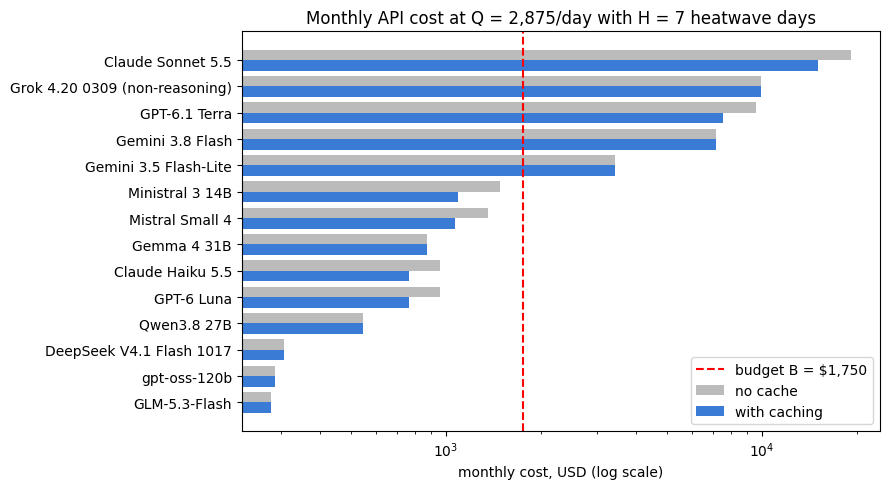

In [9]:
order = costs.sort_values("monthly $ (cache)")
fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(order))
ax.barh(y + 0.2, order["monthly $ (no cache)"], 0.4, label="no cache", color="#bbbbbb")
ax.barh(y - 0.2, order["monthly $ (cache)"], 0.4, label="with caching", color="#3a7bd5")
ax.axvline(B, color="red", ls="--", label=f"budget B = ${B:,}")
ax.set_yticks(y, order.model); ax.set_xscale("log"); ax.set_xlabel("monthly cost, USD (log scale)")
ax.legend(); ax.set_title("Monthly API cost at Q = 2,875/day with H = 7 heatwave days")
plt.tight_layout(); plt.savefig("figures/q1_monthly_cost.png", dpi=150); plt.show()

## Section 2.3 – Peak load during the heatwave window

On a heatwave day traffic is 5Q, and 35% of it arrives between 12:00 and 14:00 (120 minutes).

In [10]:
heat_day_queries = 5 * Q
window_queries = 0.35 * heat_day_queries
peak_qpm = window_queries / 120
peak_rpm = peak_qpm * CALLS_Q
peak_tpm_in = peak_qpm * IN_Q
peak_tpm_out = peak_qpm * OUT_Q
peak_tpm_uncached_in = peak_qpm * (IN_Q - CACHED_PER_QUERY)

print(f"heatwave day      = 5 x {Q:,} = {heat_day_queries:,} queries")
print(f"12:00-14:00       = 0.35 x {heat_day_queries:,} = {window_queries:,.2f} queries in 120 min")
print(f"peak queries/min  = {window_queries:,.2f} / 120 = {peak_qpm:.2f}")
print(f"peak requests/min = {peak_qpm:.2f} x {CALLS_Q:.2f} = {peak_rpm:,.1f}")
print(f"peak input TPM    = {peak_qpm:.2f} x {IN_Q:,.1f} = {peak_tpm_in:,.0f}")
print(f"peak output TPM   = {peak_qpm:.2f} x {OUT_Q:,.1f} = {peak_tpm_out:,.0f}")
print(f"peak total TPM    = {peak_tpm_in + peak_tpm_out:,.0f}")
print(f"uncached input TPM (Anthropic counts only these toward ITPM) = {peak_tpm_uncached_in:,.0f}")

heatwave day      = 5 x 2,875 = 14,375 queries
12:00-14:00       = 0.35 x 14,375 = 5,031.25 queries in 120 min
peak queries/min  = 5,031.25 / 120 = 41.93
peak requests/min = 41.93 x 8.63 = 361.8
peak input TPM    = 41.93 x 41,172.0 = 1,726,222
peak output TPM   = 41.93 x 3,270.5 = 137,123
peak total TPM    = 1,863,344
uncached input TPM (Anthropic counts only these toward ITPM) = 1,183,476


In [11]:
def limit_check(row):
    rpm, itpm, otpm = (pd.to_numeric(x, errors="coerce") for x in (row.rpm, row.itpm, row.otpm))
    if math.isnan(rpm) or math.isnan(itpm):
        return "unknown (limits not published)"
    if row.provider == "Anthropic":                       # separate input/output limits; cache reads excluded
        ok = peak_rpm <= rpm and peak_tpm_uncached_in <= itpm and peak_tpm_out <= otpm
    else:                                                 # one combined TPM (cached tokens still count for xAI)
        ok = peak_rpm <= rpm and peak_tpm_in + peak_tpm_out <= itpm
    return "fits" if ok else "EXCEEDS"

rate = pd.DataFrame({"model": models.model, "RPM limit": models.rpm, "TPM limit": models.itpm, "OTPM limit": models.otpm,
                     "rate note": models.rate_note, "peak check": [limit_check(r) for r in models.itertuples()]})
rate

,model,RPM limit,TPM limit,OTPM limit,rate note,peak check
0,GPT-6 Luna,5000,2000000,NaN,Build tier (lowest listed); TPM is combined,fits
1,GPT-6.1 Terra,5000,1000000,NaN,Build tier (lowest listed); TPM is combined,EXCEEDS
2,Claude Haiku 5.5,4000,2000000,400000.0,Start tier; cache reads excluded from ITPM,fits
3,Claude Sonnet 5.5,4000,2000000,400000.0,Start tier; cache reads excluded from ITPM,fits
4,Gemini 3.5 Flash-Lite,not reported,not reported,NaN,Tier 1 per-model limits only visible inside a signed-in AI Studio ...,unknown (limits not published)
5,Gemini 3.8 Flash,not reported,not reported,NaN,Tier 1 per-model limits only visible inside a signed-in AI Studio ...,unknown (limits not published)
6,Grok 4.20 0309 (non-reasoning),1776,10000000,NaN,Tier 0 (new account): 37 RPS and 10M TPM; RPM derived as 37 x 48 f...,fits
7,Ministral 3 14B,not reported,not reported,NaN,no OpenRouter platform cap for paid models; Mistral tier page retu...,unknown (limits not published)
8,Mistral Small 4,not reported,not reported,NaN,no OpenRouter platform cap for paid models; Mistral tier page retu...,unknown (limits not published)
9,Qwen3.8 27B,not reported,not reported,NaN,no OpenRouter platform cap for paid models; upstream provider limi...,unknown (limits not published)


## Section 2.6 – Latency budget (computed before 2.4 and 2.5, which both need it)

**Tool delay.** `latency_logger.py` called the air-quality API (OpenAQ) and the weather API (Open-Meteo) at least 20 times each per run, on two different days, and timed the heat-index function and the knowledge-base lookup locally. The assignment says to use the **median of all these measurements** as the delay for every tool call.

In [12]:
log = pd.read_csv("logs/tool_latency_log.csv")
ok = log[log["ok"] == True]
print(f"raw rows = {len(log)}, successful = {len(ok)}, failed = {len(log) - len(ok)}, distinct days = {sorted(ok['date'].unique())}")
per_tool = ok.groupby("tool")["latency_ms"].agg(["count", "median", "mean", "max"]).round(3)
display(per_tool)

pooled_median_s = ok["latency_ms"].median() / 1000
api_median_s = ok[ok["tool"].isin(["air_quality", "weather"])]["latency_ms"].median() / 1000
print(f"median of ALL measurements (as instructed) = {pooled_median_s * 1000:.3f} ms")
print(f"median of the two network APIs only        = {api_median_s * 1000:.1f} ms  (sensitivity check)")
TOOL_DELAY = pooled_median_s

raw rows = 240, successful = 236, failed = 4, distinct days = ['2026-11-09', '2026-11-10']


,count,median,mean,max
tool,,,,
air_quality,56,372.014,525.107,919.492
heat_index,60,0.011,0.013,0.178
kb_lookup,60,0.037,0.305,15.679
weather,60,529.303,531.492,718.605


median of ALL measurements (as instructed) = 0.262 ms
median of the two network APIs only        = 524.8 ms  (sensitivity check)


**Note:** half of the measurements are local functions taking under a millisecond, so the pooled median as instructed is close to zero. That would understate a real agent, where half of the tool calls are network round-trips of about 0.5–0.7 s. Below, the pooled median is used as required, and the API-only median is shown as a sensitivity check. Either way the conclusion is the same, because LLM generation time dominates.

**Latency model per LLM call.** Per-call latency = TTFT + prefill of the extra context + output tokens ÷ output speed.
* TTFT and output speed come from Artificial Analysis (`ttft_s` at the chosen setting, `output_tps`).
* Each call's input is 800 tokens longer than the previous one. AA measures TTFT on a fixed prompt, so we add the extra tokens at an **assumed** prefill rate of 5,000 tokens/s. This is an assumption, and it adds at most 1.1 s at call 8.
* **Retries:** an invalid tool call is caught before the tool runs, so a retry repeats only the LLM call. The expected extra time is $p \cdot \sum_{k<N} t_k$.
* **Total** = Σ calls + (N−1) × tool delay + retry delay.

**Choosing the two strongest candidates:** among models that (a) fit the budget with caching, (b) have a single-call TTFT below T and (c) are benchmarked by AA, take the two with the highest **tool-use** score (AutomationBench-AA). Tool selection is exactly what SaafHawa's agent loop does.

In [13]:
PREFILL_TPS = 5000          # assumption, see markdown

def call_latency(row, k, n=N):
    extra_prefill = (input_tokens(k, n) - input_tokens(1, n)) / PREFILL_TPS
    return row.ttft_s + extra_prefill + output_tokens(k, n) / row.output_tps

def query_latency(row, n=N, tool_delay=TOOL_DELAY, stream_final=False, router=None, show=False):
    turn_model = row if router is None else router      # model that runs the tool-selection turns 1..n-1
    times = [call_latency(turn_model, k, n) for k in range(1, n)] + [call_latency(row, n, n)]
    if stream_final:                                   # user sees the answer as soon as the first token streams
        times[-1] = row.ttft_s + (input_tokens(n, n) - input_tokens(1, n)) / PREFILL_TPS
    tools = (n - 1) * tool_delay
    retries = p * sum(times[:-1])
    total = sum(times) + tools + retries
    if show:
        print(f"  calls: " + " + ".join(f"{t:.2f}" for t in times) + f" = {sum(times):.2f} s")
        print(f"  tools: {n - 1} x {tool_delay:.4f} = {tools:.3f} s;  retries: {p} x {sum(times[:-1]):.2f} = {retries:.2f} s")
        print(f"  total = {total:.2f} s   (target T = {T} s)")
    return total

numeric = models.copy()
for c in ["ttft_s", "output_tps", "bench2_tool_score"]:
    numeric[c] = pd.to_numeric(numeric[c], errors="coerce")
numeric["monthly_cache"] = costs["monthly $ (cache)"]

eligible = numeric[(numeric.monthly_cache <= B) & (numeric.ttft_s < T) & numeric.bench2_tool_score.notna()]
display(eligible[["model", "monthly_cache", "ttft_s", "output_tps", "bench2_tool_name", "bench2_tool_score"]].sort_values("bench2_tool_score", ascending=False).round(2))
cand = eligible.sort_values("bench2_tool_score", ascending=False).head(2)
print("Two strongest candidates:", list(cand.model))

,model,monthly_cache,ttft_s,output_tps,bench2_tool_name,bench2_tool_score
12,DeepSeek V4.1 Flash 1017,307.97,1.32,144.0,AutomationBench-AA (non-reasoning),48.8
2,Claude Haiku 5.5,766.44,6.79,232.0,AutomationBench-AA (low),22.9
9,Qwen3.8 27B,547.56,5.31,45.0,AutomationBench-AA (non-reasoning),12.4
0,GPT-6 Luna,765.20,1.15,101.0,AutomationBench-AA (non-reasoning),9.1
10,Gemma 4 31B,871.96,3.90,36.0,AutomationBench-AA (reasoning (AA default)),4.9
8,Mistral Small 4,1065.62,1.77,147.0,AutomationBench-AA (reasoning; non-reasoning row not evaluated),1.0
7,Ministral 3 14B,1093.61,2.54,65.0,AutomationBench-AA (default),0.6
11,gpt-oss-120b,287.77,2.20,144.0,AutomationBench-AA (high; low row not evaluated),0.2


Two strongest candidates: ['DeepSeek V4.1 Flash 1017', 'Claude Haiku 5.5']


In [14]:
for row in cand.itertuples():
    print(f"\n{row.model}  (TTFT {row.ttft_s} s, {row.output_tps} tok/s)")
    base = query_latency(row, show=True)
    print(f"  with API-only tool median ({api_median_s:.3f} s): {query_latency(row, tool_delay=api_median_s):.2f} s")


DeepSeek V4.1 Flash 1017  (TTFT 1.32 s, 144.0 tok/s)
  calls: 3.75 + 3.91 + 4.07 + 4.23 + 4.39 + 4.55 + 4.71 + 6.61 = 36.22 s
  tools: 7 x 0.0003 = 0.002 s;  retries: 0.09 x 29.61 = 2.67 s
  total = 38.89 s   (target T = 9 s)
  with API-only tool median (0.525 s): 42.56 s

Claude Haiku 5.5  (TTFT 6.79 s, 232.0 tok/s)
  calls: 8.30 + 8.46 + 8.62 + 8.78 + 8.94 + 9.10 + 9.26 + 10.50 = 71.95 s
  tools: 7 x 0.0003 = 0.002 s;  retries: 0.09 x 61.45 = 5.53 s
  total = 77.48 s   (target T = 9 s)
  with API-only tool median (0.525 s): 81.15 s


Both candidates are well above T. The dominant term is **output generation**: seven tool-calling turns × 350 tokens plus a 600-token answer is about 3,050 generated tokens per query. At 100–150 tokens/s that alone is 20–30 s, before any TTFT. Below, the three suggested architectural changes are evaluated **one at a time**, and the one that helps most is recommended:

1. **Parallel independent tool calls.** Air quality, weather and the knowledge-base lookup don't depend on each other, so one LLM turn can request all three. That removes **2 LLM turns and 2 tool waits** (N: 8 → 6).
2. **Stream the final response.** The user starts reading at the final call's first token, so the final call counts only its TTFT.
3. **Route simple steps to a smaller model.** The tool-selection turns (1 … N−1) go to the fastest cheap model in the table that has tool calling; the final answer stays on the candidate.

In [15]:
fast = numeric[(numeric.ttft_s.notna()) & (numeric.output_tps.notna())].copy()
fast["turn_time"] = fast.ttft_s + 350 / fast.output_tps
router = fast.sort_values("turn_time").iloc[0]
print(f"router model for option 3: {router.model} ({router.ttft_s} s TTFT, {router.output_tps} tok/s)")
print("(if a candidate already IS the fastest model, routing changes nothing for it)")

options = []
for row in cand.itertuples():
    options.append({"model": row.model,
                    "baseline (s)": query_latency(row),
                    "1. parallel tools, N=6 (s)": query_latency(row, n=N - 2),
                    "2. stream final answer (s)": query_latency(row, stream_final=True),
                    "3. route turns 1..N-1 (s)": query_latency(row, router=router),
                    "all three combined (s)": query_latency(row, n=N - 2, stream_final=True, router=router)})
options = pd.DataFrame(options).set_index("model")
options["meets T?"] = options.min(axis=1) <= T
options.round(2)

router model for option 3: DeepSeek V4.1 Flash 1017 (1.32 s TTFT, 144.0 tok/s)
(if a candidate already IS the fastest model, routing changes nothing for it)


,baseline (s),"1. parallel tools, N=6 (s)",2. stream final answer (s),3. route turns 1..N-1 (s),all three combined (s),meets T?
model,,,,,,
DeepSeek V4.1 Flash 1017,38.89,28.47,34.72,38.89,24.31,False
Claude Haiku 5.5,77.48,57.15,74.89,42.78,29.78,False


In [16]:
# How fast would generation have to be? Output speed needed for the combined design to hit T (TTFT kept as measured).
best = cand.iloc[0]
for tps in [150, 200, 300, 400, 600, 800]:
    faster = best.copy(); faster["output_tps"] = tps
    print(f"{best.model} at {tps:3d} tok/s -> combined latency {query_latency(faster, n=N - 2, stream_final=True, router=faster):5.2f} s")

DeepSeek V4.1 Flash 1017 at 150 tok/s -> combined latency 23.78 s
DeepSeek V4.1 Flash 1017 at 200 tok/s -> combined latency 20.60 s
DeepSeek V4.1 Flash 1017 at 300 tok/s -> combined latency 17.42 s
DeepSeek V4.1 Flash 1017 at 400 tok/s -> combined latency 15.83 s
DeepSeek V4.1 Flash 1017 at 600 tok/s -> combined latency 14.24 s
DeepSeek V4.1 Flash 1017 at 800 tok/s -> combined latency 13.44 s


## Section 2.4 – Self-hosting memory

**Model:** Ministral 3 14B Instruct (Apache 2.0). It is the only open-weight model in the table with **standard full grouped-query attention**: no sliding window, no linear/latent attention. So the assignment's KV formula applies **without modification**. (The others use hybrid linear attention (Qwen3.8), sliding + global attention (Gemma 4, gpt-oss) or latent/sparse attention (Mistral Small 4, DeepSeek, GLM).)

The values are read from the model's `config.json` on Hugging Face ([S24]). A screenshot of the config is included in the report.

In [17]:
import requests
CONFIG_URL = "https://huggingface.co/mistralai/Ministral-3-14B-Instruct-2512/raw/main/config.json"
try:
    cfg = requests.get(CONFIG_URL, timeout=30).json()
except Exception:                                   # offline fallback: the snapshot saved on the access date
    cfg = {"text_config": json.load(open("data/snapshots/hf_info.json"))["mistralai/ministral-14b-2512"]["config"]}
text_cfg = cfg.get("text_config", cfg)

layers = text_cfg["num_hidden_layers"]
kv_heads = text_cfg["num_key_value_heads"]
head_dim = text_cfg.get("head_dim") or text_cfg["hidden_size"] // text_cfg["num_attention_heads"]
n_params = json.load(open("data/snapshots/hf_info.json"))["mistralai/ministral-14b-2512"]["safetensors_total"]
print(f"num_hidden_layers = {layers}, num_key_value_heads = {kv_heads}, head_dim = {head_dim}, "
      f"num_attention_heads = {text_cfg['num_attention_heads']}, sliding_window = {text_cfg.get('sliding_window')}")
print(f"parameters (safetensors total, incl. vision encoder) = {n_params:,}")

num_hidden_layers = 40, num_key_value_heads = 8, head_dim = 128, num_attention_heads = 32, sliding_window = None
parameters (safetensors total, incl. vision encoder) = 13,945,031,680


In [18]:
GB = 1e9
weights = {"FP16": n_params * 2, "8-bit": n_params * 1, "4-bit": n_params * 0.5}
for name, b in weights.items():
    print(f"weights at {name:5s} = {n_params:,} x {b / n_params:.1f} bytes = {b / GB:.2f} GB")

seq_len = input_tokens(N) + output_tokens(N)        # longest context in the loop: last call's input + its output
kv_bytes = 2 * layers * kv_heads * head_dim * seq_len * 2
print(f"\nlongest sequence = {input_tokens(N):,} input + {output_tokens(N)} output = {seq_len:,} tokens")
print(f"KV per sequence = 2 x {layers} x {kv_heads} x {head_dim} x {seq_len:,} x 2 bytes = {kv_bytes:,} bytes = {kv_bytes / GB:.3f} GB")

weights at FP16  = 13,945,031,680 x 2.0 bytes = 27.89 GB
weights at 8-bit = 13,945,031,680 x 1.0 bytes = 13.95 GB
weights at 4-bit = 13,945,031,680 x 0.5 bytes = 6.97 GB

longest sequence = 7,600 input + 600 output = 8,200 tokens
KV per sequence = 2 x 40 x 8 x 128 x 8,200 x 2 bytes = 1,343,488,000 bytes = 1.343 GB


**GPU:** NVIDIA **L40S 48 GB**, RunPod Secure Cloud on-demand, **$1.09 per hour** ([S32], page updated 2026-11-04). With 4-bit weights the model needs only about 7 GB, so a 48 GB card is enough. It is also cheaper per concurrent sequence than an H100 80 GB at $2.89/h (48 sequences for $2.89 versus 26 for $1.09).

In [19]:
GPU_NAME, GPU_MEM_GB, GPU_PRICE_HR = "NVIDIA L40S 48 GB (RunPod Secure Cloud)", 48, 1.09

usable = 0.90 * GPU_MEM_GB * GB - weights["4-bit"]
max_seqs = int(usable // kv_bytes)
print(f"usable for KV = 0.9 x {GPU_MEM_GB} GB - {weights['4-bit'] / GB:.2f} GB = {usable / GB:.2f} GB")
print(f"max concurrent sequences per GPU = floor({usable / GB:.2f} / {kv_bytes / GB:.3f}) = {max_seqs}")

usable for KV = 0.9 x 48 GB - 6.97 GB = 36.23 GB
max concurrent sequences per GPU = floor(36.23 / 1.343) = 26


**How many concurrent sessions must we serve?** By **Little's law**, concurrent sessions = arrival rate × time each session is held. A query keeps its KV cache for its whole duration (LLM turns plus tool waits). For the duration we use the self-hosted model's own latency from the 2.6 model, with Ministral 3 14B's AA speed (TTFT 2.54 s, 65 tok/s) as a proxy for our server.

In [20]:
ministral = numeric[numeric.model == "Ministral 3 14B"].iloc[0]
selfhost_latency = query_latency(ministral)

def peak_concurrency(daily_queries, latency_s=selfhost_latency):
    peak_qps = 5 * daily_queries * 0.35 / 120 / 60
    return peak_qps * latency_s

def gpus_needed(daily_queries):
    return max(1, math.ceil(peak_concurrency(daily_queries) / max_seqs))

conc = peak_concurrency(Q)
print(f"self-hosted query latency = {selfhost_latency:.1f} s")
print(f"peak arrival = {peak_qpm:.2f} queries/min = {peak_qpm / 60:.3f} queries/s")
print(f"peak concurrent sessions = {peak_qpm / 60:.3f} x {selfhost_latency:.1f} = {conc:.1f}")
print(f"GPUs needed = ceil({conc:.1f} / {max_seqs}) = {gpus_needed(Q)}")

self-hosted query latency = 77.0 s
peak arrival = 41.93 queries/min = 0.699 queries/s
peak concurrent sessions = 0.699 x 77.0 = 53.8
GPUs needed = ceil(53.8 / 26) = 3


## Section 2.5 – Break-even analysis

* **Self-hosting:** monthly cost = GPUs(Q) × $1.09 × 24 × 30, with every GPU billed for the full month. GPUs(Q) grows in **steps** whenever peak concurrency passes another multiple of the per-GPU capacity.
* **API:** the candidate from 2.6 that meets T after the change; if neither does, the one with the lower latency. Its monthly cost scales linearly with volume: queries per month $= Q(30 - H) + 5QH = Q(30 + 4H)$.
* Q* is the smallest daily volume at which self-hosting becomes cheaper.

In [21]:
best_latency = options.drop(columns="meets T?").min(axis=1)
meets = options[options["meets T?"]]
api_name = (meets.index[0] if len(meets) == 1 else
            costs.set_index("model").loc[meets.index, "monthly $ (cache)"].idxmin() if len(meets) > 1 else
            best_latency.idxmin())
api_row = models[models.model == api_name].iloc[0]
print(f"API comparator: {api_name}  ({'meets T' if api_name in meets.index else 'neither meets T; lower latency'})")

def api_monthly(daily_queries):
    return monthly_cost(api_row, True, queries=daily_queries * (30 + 4 * H))

def selfhost_monthly(daily_queries):
    return gpus_needed(daily_queries) * GPU_PRICE_HR * 24 * 30

volumes = np.concatenate([np.arange(10, 1000, 10), np.arange(1000, 200_001, 100)])     # finer steps at low volume
api_curve = np.array([api_monthly(v) for v in volumes])
self_curve = np.array([selfhost_monthly(v) for v in volumes])
cheaper = volumes[self_curve < api_curve]
Q_star = int(cheaper[0]) if len(cheaper) else None
print(f"self-hosting at Q = {Q:,}: {gpus_needed(Q)} GPU(s) -> ${selfhost_monthly(Q):,.0f}/month;  API: ${api_monthly(Q):,.0f}/month")
print(f"Q* = {Q_star:,} queries/day" if Q_star else "self-hosting never becomes cheaper in the scanned range (10 to 200,000/day)")

API comparator: DeepSeek V4.1 Flash 1017  (neither meets T; lower latency)
self-hosting at Q = 2,875: 3 GPU(s) -> $2,354/month;  API: $308/month
self-hosting never becomes cheaper in the scanned range (10 to 200,000/day)


**Why there may be no crossover.** Both costs grow roughly linearly with Q, so the result depends only on the **cost per query**. Self-hosting has to be sized for the heatwave midday peak, but it is paid for every hour of the month. The table below shows the ratio, then repeats the break-even for **every** API model, so the reader can see against which prices self-hosting would win.

In [22]:
avg_qpm = monthly_queries / MINUTES_PER_MONTH
print(f"average load = {monthly_queries:,} / {MINUTES_PER_MONTH:,} min = {avg_qpm:.2f} queries/min;  peak = {peak_qpm:.2f}  ->  peak/average = {peak_qpm / avg_qpm:.1f}x")
print(f"self-host $ per query at large Q ~ {GPU_PRICE_HR * 720 / max_seqs * peak_concurrency(1) / (30 + 4 * H):.5f}")
print(f"API $ per query ({api_name})   = {api_monthly(1) / (30 + 4 * H):.5f}")

def q_star(row):
    api = np.array([monthly_cost(row, True, queries=v * (30 + 4 * H)) for v in volumes])
    hit = volumes[self_curve < api]
    return int(hit[0]) if len(hit) else None

breakeven = pd.DataFrame({"API model": models.model, "side": models.side,
                          "API $/month at Q": costs["monthly $ (cache)"].round(0),
                          "Q* (queries/day)": [q_star(r) for r in models.itertuples()]})
breakeven["Q* / our Q"] = (breakeven["Q* (queries/day)"] / Q).round(1)
breakeven.sort_values("API $/month at Q")

average load = 166,750 / 43,200 min = 3.86 queries/min;  peak = 41.93  ->  peak/average = 10.9x
self-host $ per query at large Q ~ 0.00974
API $ per query (DeepSeek V4.1 Flash 1017)   = 0.00185


,API model,side,API $/month at Q,Q* (queries/day),Q* / our Q
13,GLM-5.3-Flash,open,279.0,NaN,NaN
11,gpt-oss-120b,open,288.0,NaN,NaN
12,DeepSeek V4.1 Flash 1017,open,308.0,NaN,NaN
9,Qwen3.8 27B,open,548.0,NaN,NaN
0,GPT-6 Luna,closed,765.0,NaN,NaN
2,Claude Haiku 5.5,closed,766.0,NaN,NaN
10,Gemma 4 31B,open,872.0,NaN,NaN
8,Mistral Small 4,open,1066.0,NaN,NaN
7,Ministral 3 14B,open,1094.0,NaN,NaN
4,Gemini 3.5 Flash-Lite,closed,3423.0,660.0,0.2


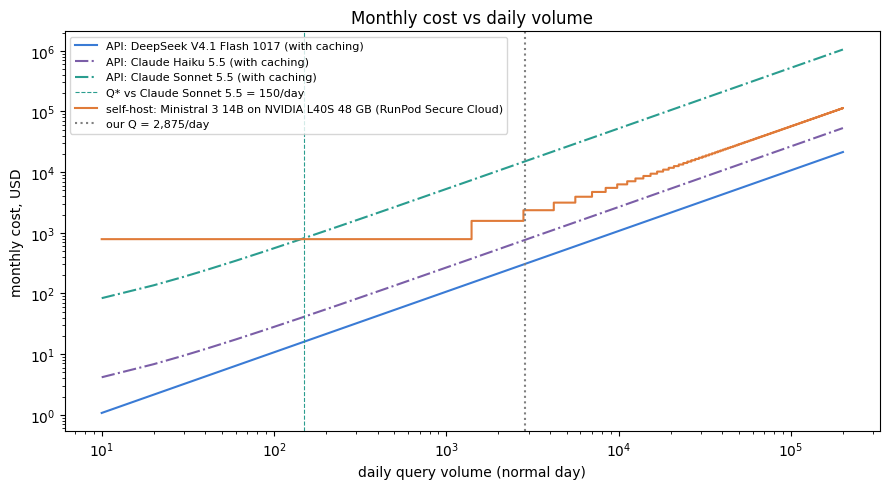

In [23]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(volumes, api_curve, label=f"API: {api_name} (with caching)", color="#3a7bd5")
for other, colour in [(m, c) for m, c in zip(list(cand.model) + ["Claude Sonnet 5.5"], ["#3a7bd5", "#7b5ea7", "#2a9d8f"]) if m != api_name]:
    r_other = models[models.model == other].iloc[0]
    curve = [monthly_cost(r_other, True, queries=v * (30 + 4 * H)) for v in volumes]
    ax.plot(volumes, curve, label=f"API: {other} (with caching)", color=colour, ls="-.")
    qs = q_star(r_other)
    if qs:
        ax.axvline(qs, color=colour, ls="--", lw=0.8, label=f"Q* vs {other} = {qs:,}/day")
ax.step(volumes, self_curve, where="post", label=f"self-host: Ministral 3 14B on {GPU_NAME}", color="#e07b39")
ax.axvline(Q, color="gray", ls=":", label=f"our Q = {Q:,}/day")
if Q_star:
    ax.axvline(Q_star, color="green", ls="--", label=f"Q* = {Q_star:,}/day")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("daily query volume (normal day)"); ax.set_ylabel("monthly cost, USD")
ax.set_title("Monthly cost vs daily volume"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("figures/q1_breakeven.png", dpi=150); plt.show()

### Is Q* realistic?
Against the API we would actually use (DeepSeek V4.1 Flash, $308/month), **there is no Q\***. Self-hosting costs about $0.0097 per query against the API's $0.0019, and because both grow linearly, more volume never closes that gap. The reason is structural: the GPUs are sized for the 12:00–14:00 heatwave peak, which is **10.9× the average load**, but they are billed 24 h × 30 days. Self-hosting only wins against the premium closed models (Claude Sonnet 5.5, Grok 4.20, GPT-6.1 Terra, Gemini 3.x), where Q* is 150–660 queries/day, far below our 2,875. Self-hosting could become competitive if the GPUs autoscaled (paid only during peak hours), or with a higher-throughput serving stack than the 65 tok/s per stream assumed here.

## Conclusions

1. **Cost (2.1–2.2).** SaafHawa uses 6.87 B input and 0.55 B output tokens per month. Nine of the fourteen models fit the $1,750 budget. Prompt caching cuts the Claude Haiku 5.5 bill from $959 to $766 (−20%). Gemini 3.x, GPT-6.1 Terra, Grok 4.20 and Claude Sonnet 5.5 are 2–9× over budget even with caching.
2. **Peak load (2.3).** The heatwave midday peak is 41.9 queries/min, which is 362 requests/min and 1.86 M tokens/min. GPT-6.1 Terra's new-account limit (1 M TPM) would throttle it. GPT-6 Luna, both Claude models and Grok fit. For Gemini and every open-weight host the limits are not published, so whether they fit is **unknown**.
3. **Latency (2.6).** **Neither candidate meets T = 9 s.** DeepSeek V4.1 Flash takes 38.9 s and Claude Haiku 5.5 takes 77.5 s. The time goes into generating about 3,050 output tokens across eight sequential turns; the tools themselves add under 0.6 s per call. The single best change is **parallel tool calls** (DeepSeek drops to 28.5 s). Combining all three changes reaches 24.3 s. Even at 800 tok/s the combined design still needs 13.4 s, so meeting 9 s also requires **shorter tool-selection turns**: a compact JSON tool call is about 50 tokens, not 350.
4. **Self-hosting (2.4–2.5).** Ministral 3 14B needs 6.97 GB at 4-bit plus 1.34 GB of KV cache per 8,200-token session, which fits 26 sessions on a 48 GB L40S. The peak needs about 54 concurrent sessions, so **3 GPUs, costing $2,354/month**. That is over budget and 7.6× the DeepSeek API. On top of that, Ministral scores only 0.6% on AutomationBench-AA, so it could not do SaafHawa's tool-calling job anyway.
5. **Recommendation.** Use **DeepSeek V4.1 Flash 1017 through an API**. It is the cheapest model that is any good at tool use (48.8% on AutomationBench-AA, close to Claude Sonnet 5.5 at low effort), it has the fastest time to first token, and it costs $308/month. Redesign the agent loop with parallel tool calls, streamed answers and short JSON tool calls. Before launch, **get a written rate-limit quota from the host**: its limits are unpublished, and that is the main risk of this choice. **Claude Haiku 5.5** is the fallback: its limits are documented and fit the peak, and it has caching, but it is 2.5× the price and much slower at the `low` setting.